# Customer Segmentation using Unsupervised Learning

## Module: AI and Machine Learning (ST1511)

## Assignment: CA2 – Part A

## Student Name: Kendrick Slamat

## Student ID: p2510877

**GRADING CRITERIA (50 marks total):**

-   Machine Learning Workflow: 10 marks
-   Exploratory Data Analysis: 10 marks
-   Preprocessing & Feature Engineering: 10 marks
-   Modelling and Evaluation: 10 marks
-   Result Analysis: 10 marks


**Background:**
We collected the information of 200 customers including their Gender, Age, Income
and How much they spend. We want to group the customers into clusters so that we
can cater the needs for different customers.

**Business Questions to Answer:**

1. How to perform customer segmentation using unsupervised machine learning?
2. What are the characteristics of each customer cluster?
3. Which group of customers needs more attention?

**Dataset:** `CA2-Customer-Data.csv`

**Approach:** We will use unsupervised learning (clustering) to solve the problem. Clustering allows us to differentiate customers and separate them into separate groups of customers with similar interests. This ensures that customers can receive more tailored solutions based on the problem.


**Machine Learning Workflow**:

1. **Data Understanding** - Load and explore the dataset
2. **Exploratory Data Analysis (EDA)** - Visualize patterns and distributions
3. **Data Preprocessing** - Handle missing values, scale features
4. **Feature Engineering** - Create new meaningful features
5. **Model Building** - Apply multiple clustering algorithms
6. **Model Evaluation** - Compare clusters using metrics
7. **Result Analysis** - Interpret clusters and make recommendations


## SECTION 1: Load and examine Datasets, and Perform Explanatory Data Analysis on the dataset.

**Objective:** Load the dataset and understand its structure. We will use `.info()`, `.describe()` and `.head()` to understand the dataset better. By completing proper EDA, we will be able to understand the distribution and discover underlying relationships between features within the dataset.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import make_pipeline
from scipy.cluster.hierarchy import dendrogram, linkage
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Suppress warnings for unused imports
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', None)
plt.style.use("dark_background")
color_palette = [
    "#3d7bc5",  
    "#c45b9a",  
    "#2f8a46",  
    "#c56a2f",  
    "#d45a4f",  
    "#6e7681",  
    "#9aa4b1",
]
sns.set_theme(
    context="notebook",
    style="darkgrid",
    palette=color_palette,
    rc={
        "axes.facecolor": "#0d1117",
        "figure.facecolor": "#0d1117",
        "axes.edgecolor": "#30363d",
        "grid.color": "#30363d",
        "text.color": "#c9d1d9",
        "axes.labelcolor": "#c9d1d9",
        "xtick.color": "#8b949e",
        "ytick.color": "#8b949e",
        "axes.titleweight": "bold",
        "axes.titlepad": 14,
        "legend.frameon": False,
        },
)

In [3]:
path = "datasets/CA2-Customer-Data.csv"
df = pd.read_csv(path)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   CustomerID           200 non-null    int64 
 1   Gender               200 non-null    object
 2   Age                  200 non-null    int64 
 3   Income (k$)          200 non-null    int64 
 4   How Much They Spend  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [5]:
df.describe()

,CustomerID,Age,Income (k$),How Much They Spend
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [6]:
df.head()

,CustomerID,Gender,Age,Income (k$),How Much They Spend
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


**Dataset Insights:**

The dataset contains **200** rows (each row is a customer) and **4** columns. The columns are:

-   **CustomerID**: Unique identifier for each customer (number,primary key)
-   **Gender**: Customer gender (Male/Female) (string)
-   **Age**: Age of the customer (years) (number)
-   **Income (k$)**: Annual income in thousands of dollars ($)
-   **How Much They Spend**: Amount of money spent in the shop ($)

Now that we have explored the dataset, we can perform extended explanatory data analysis on the dataset, involving data cleaning.


\*Objective:\*\* Understand the data distribution and relationships between variables

**HINT:** Good EDA includes:

-   Checking data types and missing values
-   Summary statistics (mean, median, std, min, max)
-   Distributions (histograms)
-   Relationships between variables (scatter plots, pair plots)
-   Outlier detection


In [7]:
# TODO: Check basic information about the dataset
# Use df.info() to see data types and non-null counts
# Use df.describe() to see statistical summary
# Check for missing values using df.isnull().sum()
# Your code here:

In [8]:
# Check for null values in dataset
df.isnull().sum()

CustomerID             0
Gender                 0
Age                    0
Income (k$)            0
How Much They Spend    0
dtype: int64

In [9]:
# Check for duplicate values in the dataset
duplicates = df[df.duplicated()]

if not duplicates.empty: 
    print(duplicates.head(5))
else:
    print("No duplicates found in the Dataset.")

No duplicates found in the Dataset.


Since most of our data is numerical, we can analyze each feature visually by plotting some graphs.


In [10]:
df.columns

Index(['CustomerID', 'Gender', 'Age', 'Income (k$)', 'How Much They Spend'], dtype='object')

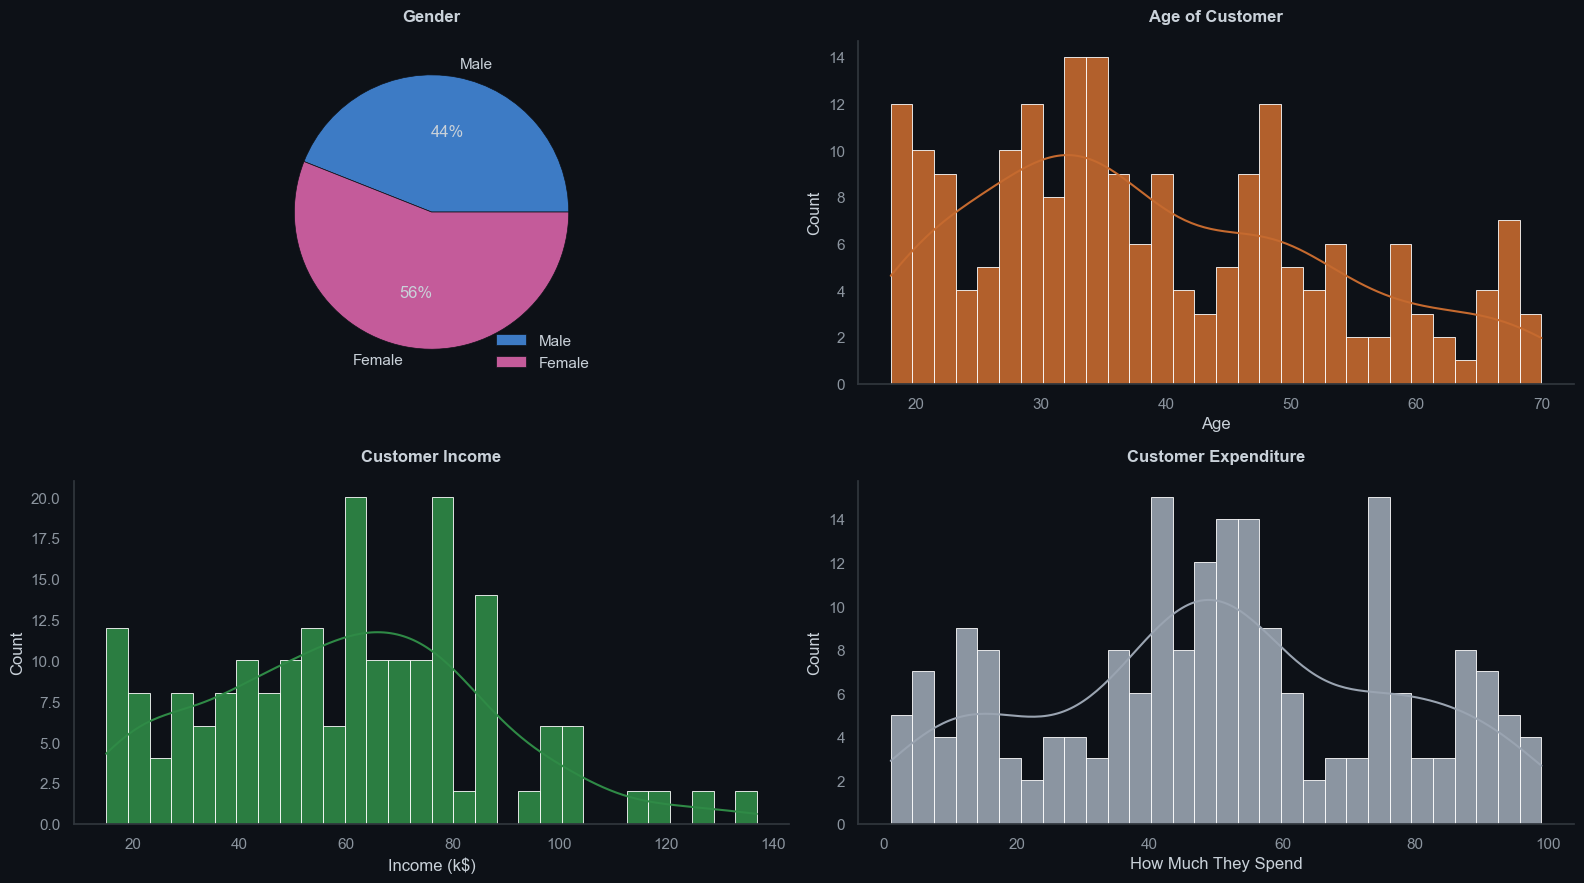

In [11]:
plt.figure(figsize=(16,9))
plt.subplot(2,2,1)

# First feature: Gender
data = [df["Gender"][df["Gender"] == "Male"].count(), df["Gender"][df["Gender"] == "Female"].count()]
labels = ["Male","Female"]
plt.pie(data, labels=labels, colors=color_palette, autopct='%.0f%%',wedgeprops={"edgecolor": "#0d1117", "linewidth": 0.5})
plt.title("Gender")
plt.legend(labels,loc="lower right")

# Second feature: Age
plt.subplot(2,2,2)
plt.title("Age of Customer")
sns.histplot(df,x="Age",bins=30,kde=True,color=color_palette[3],edgecolor="#ffffff", linewidth=0.6, alpha=0.9)
plt.grid(False) 
sns.despine()


# Third feature: Income
plt.subplot(2,2,3)
plt.title("Customer Income")
sns.histplot(df,x="Income (k$)",bins=30,kde=True,color=color_palette[2],edgecolor="#ffffff", linewidth=0.6, alpha=0.9)
plt.grid(False) 
sns.despine()

# Fourth feature: Spending
plt.subplot(2,2,4)
plt.title("Customer Expenditure")
sns.histplot(df,x="How Much They Spend",bins=30,kde=True,color=color_palette[6],edgecolor="#ffffff", linewidth=0.6, alpha=0.9)
plt.grid(False) 
sns.despine()

plt.tight_layout()
plt.show()

In [12]:
df.describe()

,CustomerID,Age,Income (k$),How Much They Spend
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


**From the dataset**:

-   Total customers: 200
-   Missing values: NO
-   Duplicates: NO
-   Data types: Numerical = [Age, Income (k$), How Much They Spend]; Categorical = [Gender]
-   Age range: 18 to 70 years
-   Income range: 15 to 137 thousand dollars
-   Spending range: 1 to 99 dollars

**From the charts:**

-   Gender: Slight female majority (~56% Female vs ~44% Male).
-   Age: Broad, slightly bimodal with peaks in late 20s–early 30s and mid-40s–50s; tail thins after 60.
-   Income: Right-skewed with concentration around 50–80k and few high earners >100k.
-   Spending: Fairly spread 10–90 with a hump around 40–60 and fewer at extremes.
-   Visual hint of multiple groups: mid-income/mid-spend vs high-income/mid-spend vs lower-income/varied spend.


### Data Visualization

We will now be performing data visualization to visually analyze relationships between variables and discover new trends.


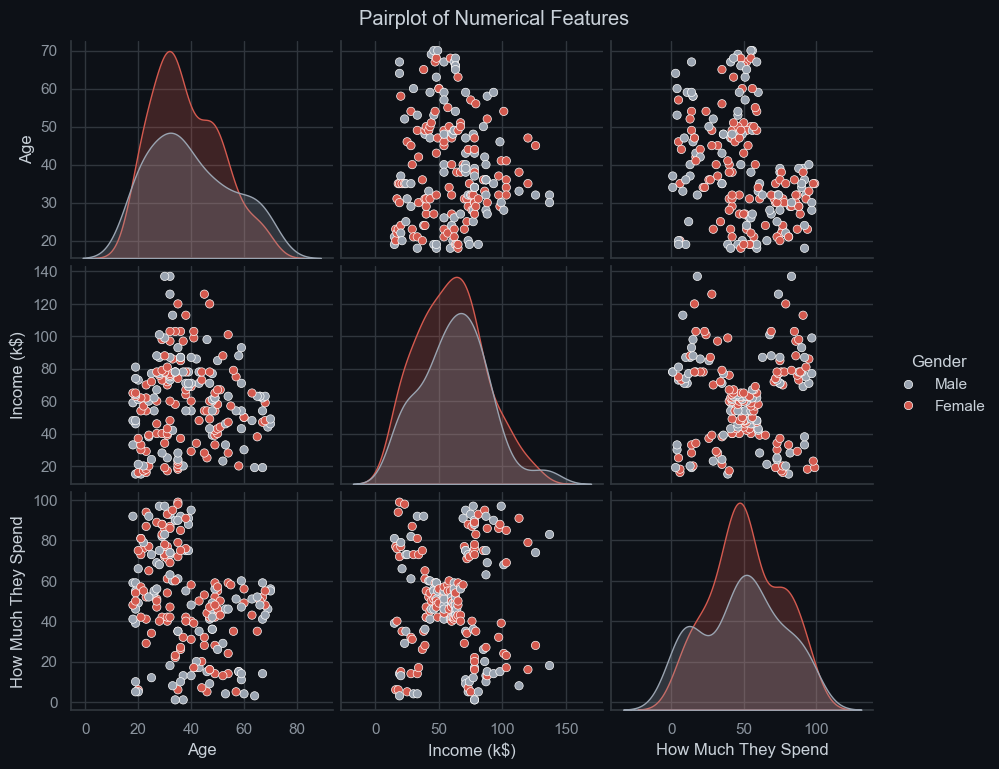

In [13]:
pp = sns.pairplot(df.drop(columns=['CustomerID']), hue='Gender',aspect=1.2, palette=[color_palette[6], color_palette[4]])
pp.figure.suptitle("Pairplot of Numerical Features", y=1.02)
plt.show()

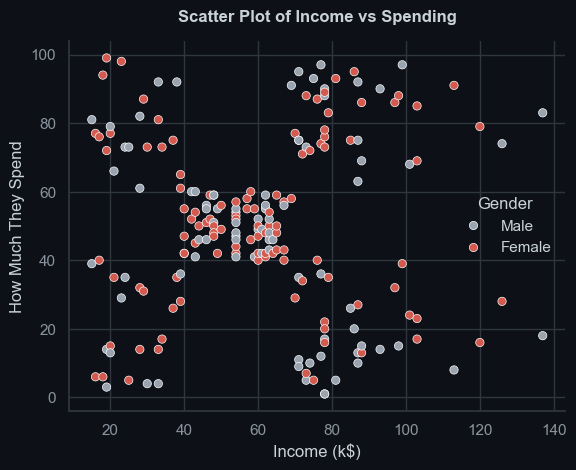

In [14]:
sns.scatterplot(data=df, x="Income (k$)", y="How Much They Spend", hue="Gender", palette=[color_palette[6], color_palette[4]])
plt.xlabel("Income (k$)")
plt.ylabel("How Much They Spend")
plt.title("Scatter Plot of Income vs Spending")
sns.despine()

plt.show()

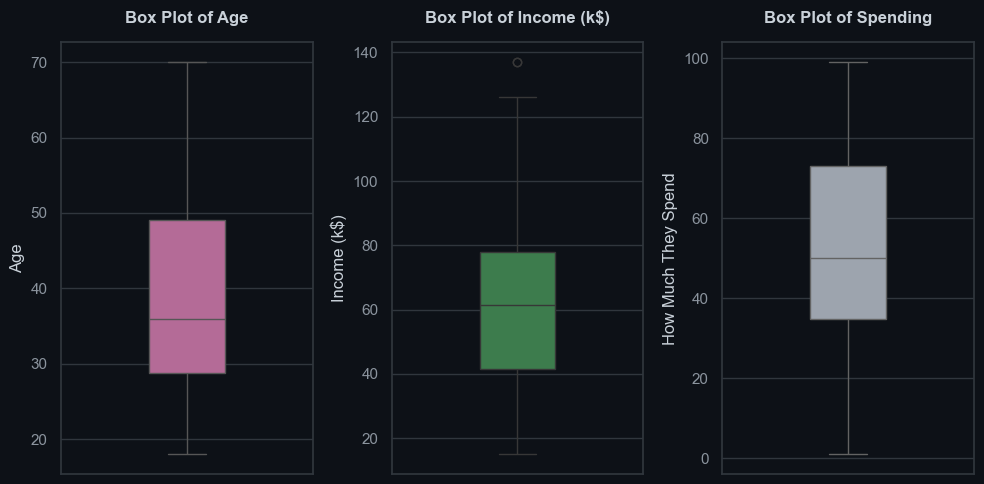

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(10, 5))
sns.boxplot(y=df["Age"], ax=axes[0], color=color_palette[1], width=0.3, saturation=0.7)
axes[0].set_title("Box Plot of Age")
sns.boxplot(y=df["Income (k$)"], ax=axes[1], color=color_palette[2], width=0.3, saturation=0.7)
axes[1].set_title("Box Plot of Income (k$)")
sns.boxplot(y=df["How Much They Spend"], ax=axes[2], color=color_palette[6], width=0.3, saturation=0.7)
axes[2].set_title("Box Plot of Spending")

plt.tight_layout()
plt.show()

1. **Age distribution:**

    - The age distribution has 1 distinct peak in the mid-30s range. This suggests two primary customer cohorts—younger professionals and mid-career individuals. Overall, the distribution is fairly broad (18–70 years) but not normally distributed.

2. **Income vs Spending relationship:**

    - There is a moderate positive correlation between income and spending—higher earners tend to spend more, but the relationship is not perfectly linear. Notably, the scatter plot reveals distinct clusters: (a) mid-income earners ($50–80k) with moderate spending ($30–60), (b) high-income earners ($80–137k) with variable spending, and (c) lower-income customers ($15–50k) with more erratic spending patterns. This suggests income alone does not fully predict spending behavior.

3. **Gender differences:**

    - Gender is relatively balanced in the dataset (44% Male, 56% Female). The pairplot and scatter plots show no dramatic gender-based differences in income or spending distributions. However, there is a slight tendency for females to have marginally higher average income and spending compared to males, though the difference is minimal.

4. **Outliers:**

    - Box plots reveal one potential outlier: very high earners (>130k) relative to their income. However, these are not extreme enough to warrant removal—they likely represent genuine business segments (e.g., high-income savers or budget-conscious wealthy individuals). No data quality issues detected.

5. **Potential clusters:**
    - Yes, the visualizations strongly hint at at least 3 natural customer groups:
        - **High-Income Moderate Spenders**: Income 80–137k, spending 30–70
        - **Mid-Income Steady Spenders**: Income 50–80k, spending 35–65
        - **Lower-Income Variable Spenders**: Income 15–50k, spending 10–90
    - These natural separations justify proceeding with k-means or hierarchical clustering with k likely in the range of 3–4.


---

## SECTION 2: Data Preprocessing

**Objective:** Prepare the data for clustering

**WHY PREPROCESSING IS IMPORTANT:**

-   Clustering algorithms use distance calculations
-   Features with larger scales will dominate the distance
-   Example: Income (10-150k) vs Age (18-70) - Income would have much more influence
-   **Solution:** Scale all features to the same range

**STEPS:**

1. Select features for clustering (numerical columns only)
2. Scale the features using StandardScaler
3. Handle any missing values (if found)


In [16]:
features = df[['Age', 'Income (k$)', 'How Much They Spend']]
print(f"Features shape: {features.shape}")

Features shape: (200, 3)


In [17]:
# Create a StandardScaler object and fit/transform data with the scaler

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

# Convert back to DataFrame for easier handling
scaled_df = pd.DataFrame(scaled_features, columns=features.columns)

print(f"Mean of scaled features: {scaled_features.mean(axis=0)}")
print(f"Standard Deviation of scaled features: {scaled_features.std(axis=0)}")

Mean of scaled features: [-1.02140518e-16 -2.13162821e-16 -1.46549439e-16]
Standard Deviation of scaled features: [1. 1. 1.]


---

## SECTION 3: Feature Engineering

**Objective:** Create at least one new meaningful feature

**WHY CREATE NEW FEATURES:**

-   Sometimes combining existing features reveals better patterns
-   Example: Spending/Income ratio tells us about spending behavior
-   A high ratio means someone spends a lot relative to their income
-   A low ratio means someone saves more

**RUBRIC REQUIREMENT:** You MUST create at least one new feature and justify why it's useful!


In [18]:
# Formula: Spending / Income
# This shows what percentage of income is spent
df['Income_Spending_Ratio'] = df['How Much They Spend'] / df['Income (k$)']

# Display the new feature
df[['Income (k$)', 'How Much They Spend', 'Income_Spending_Ratio']].head(10)

,Income (k$),How Much They Spend,Income_Spending_Ratio
0,15,39,2.600000
1,15,81,5.400000
2,16,6,0.375000
3,16,77,4.812500
4,17,40,2.352941
5,17,76,4.470588
6,18,6,0.333333
7,18,94,5.222222
8,19,3,0.157895
9,19,72,3.789474


In [19]:
# Create categorical features based on Income and Spending

# Income_Category: Low (<50), Medium (50-90), High (>90)
df['Income_Category'] = np.where(
    df['Income (k$)'] < 50, 'Low',
    np.where(df['Income (k$)'] <= 90, 'Medium', 'High')
)

# Spending_Category: Frugal (<30), Moderate (30-60), High-Spender (>60)
df['Spending_Category'] = np.where(
    df['How Much They Spend'] < 30, 'Frugal',
    np.where(df['How Much They Spend'] <= 60, 'Moderate', 'High-Spender')
)

df = pd.get_dummies(df, columns=['Income_Category', 'Spending_Category'])

df[['Income (k$)','How Much They Spend',"Income_Category_Low", "Income_Category_Medium", "Income_Category_High", "Spending_Category_Frugal", "Spending_Category_Moderate", "Spending_Category_High-Spender"]].head()

,Income (k$),How Much They Spend,Income_Category_Low,Income_Category_Medium,Income_Category_High,Spending_Category_Frugal,Spending_Category_Moderate,Spending_Category_High-Spender
0,15,39,True,False,False,False,True,False
1,15,81,True,False,False,False,False,True
2,16,6,True,False,False,True,False,False
3,16,77,True,False,False,False,False,True
4,17,40,True,False,False,False,True,False


In [20]:
df.head()

,CustomerID,Gender,Age,Income (k$),How Much They Spend,Income_Spending_Ratio,Income_Category_High,Income_Category_Low,Income_Category_Medium,Spending_Category_Frugal,Spending_Category_High-Spender,Spending_Category_Moderate
0,1,Male,19,15,39,2.600000,False,True,False,False,False,True
1,2,Male,21,15,81,5.400000,False,True,False,False,True,False
2,3,Female,20,16,6,0.375000,False,True,False,True,False,False
3,4,Female,23,16,77,4.812500,False,True,False,False,True,False
4,5,Female,31,17,40,2.352941,False,True,False,False,False,True


In [21]:
df_new = df[['Age', 'Income (k$)', 'How Much They Spend', 'Income_Spending_Ratio']]
scaled_new = scaler.fit_transform(df_new)
scaled_df_new = pd.DataFrame(scaled_new, columns=df_new.columns).merge(df[["Income_Category_Low", "Income_Category_Medium", "Income_Category_High", "Spending_Category_Frugal", "Spending_Category_Moderate", "Spending_Category_High-Spender"]], left_index=True, right_index=True)

print("Feature engineering completed!")
print(f"Final feature shape: {scaled_df_new.shape}")

Feature engineering completed!
Final feature shape: (200, 10)


## Feature Justification

**Spending_Income_Ratio** captures how aggressively a customer spends relative to their earning power. It normalizes spending by income, so a $50 spender on $40k income is different from a $50 spender on $120k income. This ratio highlights high-value enthusiasts (high spend vs income) versus savers (low spend vs income), improving cluster separation on behavioral intensity, not just absolute dollars. Business insight: target high-ratio customers with loyalty perks to retain, and low-ratio high-income customers with cross-sell/upsell offers.

**Income_Category (Low/Medium/High)** bins income to expose discrete affordability tiers. It makes clusters more interpretable and stabilizes distance-based methods by reducing sensitivity to income outliers. Business insight: tailor pricing and product bundles by tier.

**Spending_Category (Frugal/Moderate/High-Spender)** bins spending behavior, highlighting wallet-share differences. It separates occasional/frugal buyers from heavy spenders, aiding clear cluster narratives and marketing personalization. Business insight: design differentiated promotions (e.g., frugal: entry offers; high-spender: VIP/loyalty).


---

## SECTION 4: Model Building

**Objective:** Apply multiple clustering algorithms

**IMPORTANT:** The assignment requires you to use MORE than one clustering algorithm!

We will use either two of the three algorithms:

1. **K-Means Clustering** - Most popular, fast, works well with spherical clusters
2. **Hierarchical Clustering** - Creates a tree of clusters, doesn't need k specified upfront
3. **Gaussian Mixture Model (GMM)** - Probabilistic approach, flexible cluster shapes

But first, we need to determine the optimal number of clusters (k)!


### 5.1 Determining Optimal Number of Clusters

**Methods to find k:**

1. **Elbow Method** - Plot inertia vs k, look for the "elbow"
2. **Silhouette Score** - Measures how similar a point is to its cluster vs other clusters


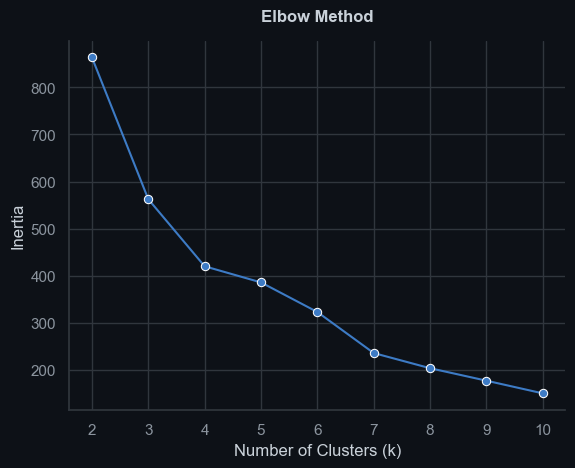

Inertias: [863.58 562.46 420.06 385.78 322.94 235.82 203.62 177.14 150.23]


In [22]:
inertias = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_df_new)
    inertias.append(kmeans.inertia_)

sns.lineplot(x=list(k_range), y=inertias, marker='o',palette=color_palette)
sns.despine()
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()
print("Inertias:", np.round(inertias, 2))


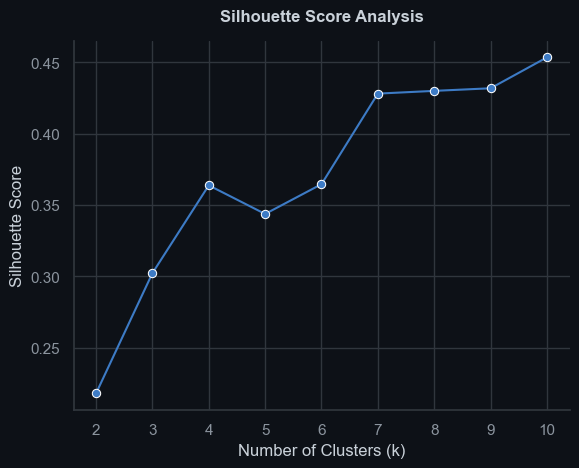

Silhouette Scores: [0.22 0.3  0.36 0.34 0.36 0.43 0.43 0.43 0.45]


In [23]:

silhouette_scores = []
k_range = range(2, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_df_new)
    silhouette_score_value = silhouette_score(scaled_df_new, kmeans.labels_)
    silhouette_scores.append(silhouette_score_value)



sns.lineplot(x=list(k_range), y=silhouette_scores, marker='o',palette=color_palette)
sns.despine()
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Analysis')
plt.show()
print("Silhouette Scores:", np.round(silhouette_scores, 2))

Based on the Elbow Method and Silhouette Score:

-   Elbow Method suggests: k = 7 (because inertia drops at around 7)
-   Silhouette Score is highest at: k = 10
-   **My chosen k:** : 7. It balances the elbow inflection with good (though not peak) silhouette, keeps clusters interpretable for 200 customers, and aligns with the visible 3–4 natural groups plus sub-structure. k=10 adds marginal score gain but risks over-fragmenting segments for business actionability.


In [24]:
k = 7
model_df = df[['Age', 'Income (k$)', 'How Much They Spend', 'Income_Spending_Ratio',"Income_Category_Low", "Income_Category_Medium", "Income_Category_High", "Spending_Category_Frugal", "Spending_Category_Moderate", "Spending_Category_High-Spender"]]

### 5.2 K-Means Clustering


In [25]:
# Create a model pipeline with scaling and KMeans
num_features = ['Age', 'Income (k$)', 'How Much They Spend', 'Income_Spending_Ratio']
cat_features = ['Income_Category_Low', 'Income_Category_Medium', 'Income_Category_High', 'Spending_Category_Frugal', 'Spending_Category_Moderate', 'Spending_Category_High-Spender']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', 'passthrough', cat_features)
    ]
)

kmeans = KMeans(n_clusters=k, random_state=42)
pipeline = make_pipeline(preprocessor, kmeans)

# Fit the pipeline to the data
pipeline.fit(model_df)

# Predict cluster labels
df['KMeans_Cluster'] = pipeline.predict(model_df)

# Display cluster counts
print("K-Means Cluster Distribution:")
print(df['KMeans_Cluster'].value_counts().sort_index())

K-Means Cluster Distribution:
KMeans_Cluster
0    48
1    39
2    25
3    11
4    22
5    19
6    36
Name: count, dtype: int64


### 5.3 Hierarchical Clustering


In [26]:
hierarchical = AgglomerativeClustering(n_clusters=k, linkage='ward')
pipeline = make_pipeline(preprocessor,hierarchical)

# Fit the pipeline to the data
pipeline.fit(model_df)

# Predict cluster labels
df['Hierarchical_Cluster'] = pipeline.named_steps['agglomerativeclustering'].labels_


# Display cluster counts
print("Hierarchical Cluster Distribution:")
print(df['Hierarchical_Cluster'].value_counts().sort_index())

Hierarchical Cluster Distribution:
Hierarchical_Cluster
0    34
1    39
2    23
3    33
4    38
5    15
6    18
Name: count, dtype: int64


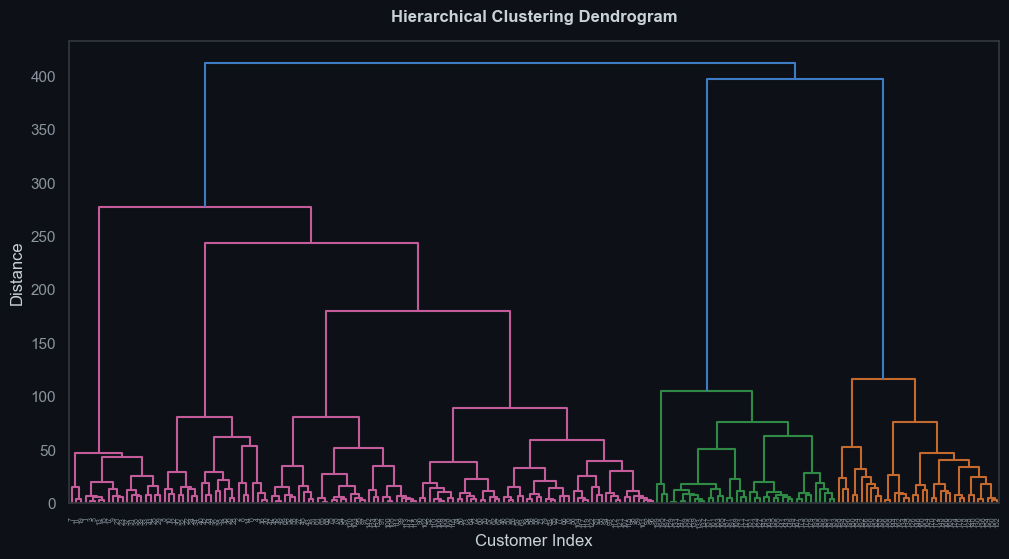

In [27]:
linkage_matrix = linkage(df_new, method='ward')
plt.figure(figsize=(12, 6))
dendrogram(linkage_matrix)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Customer Index')
plt.ylabel('Distance')
plt.grid(False)
plt.show()

### 5.4 Gaussian Mixture Model (GMM)


In [28]:
gmm = GaussianMixture(n_components=k, random_state=42)

pipeline = make_pipeline(preprocessor,gmm)

# Fit the pipeline to the data
pipeline.fit(model_df)

# Predict cluster labels
df['GMM_Cluster'] = pipeline.predict(model_df)

# Display cluster counts
print("GMM Cluster Distribution:")
print(df['GMM_Cluster'].value_counts().sort_index())

GMM Cluster Distribution:
GMM_Cluster
0    58
1    39
2    25
3    11
4    22
5    19
6    26
Name: count, dtype: int64


---

## SECTION 5: Model Evaluation

**Objective:** Compare the three clustering algorithms using evaluation metrics

**Metrics we'll use:**

1. **Silhouette Score** (higher is better, range: -1 to 1)

These metrics help us determine which algorithm found the "best" clusters.


In [29]:
results = []
for model, label in [('K-Means', 'KMeans_Cluster'), 
                                ('Hierarchical', 'Hierarchical_Cluster'),
                                ('GMM', 'GMM_Cluster')]:
    silhouette = silhouette_score(df_new, df[label])
    davies = davies_bouldin_score(df_new, df[label])
    calinski = calinski_harabasz_score(df_new, df[label])
    
    results.append({
        'Model': model,
        'Silhouette Score': silhouette,
        "Davies-Bouldin Score": davies,
        "Calinski-Harabasz Score": calinski
    })

results_df = pd.DataFrame(results)
print(results_df)

          Model  Silhouette Score  Davies-Bouldin Score  \
0       K-Means          0.422397              0.851826   
1  Hierarchical          0.366120              0.968183   
2           GMM          0.404536              0.851765   

   Calinski-Harabasz Score  
0               154.102366  
1               131.813001  
2               145.940309  


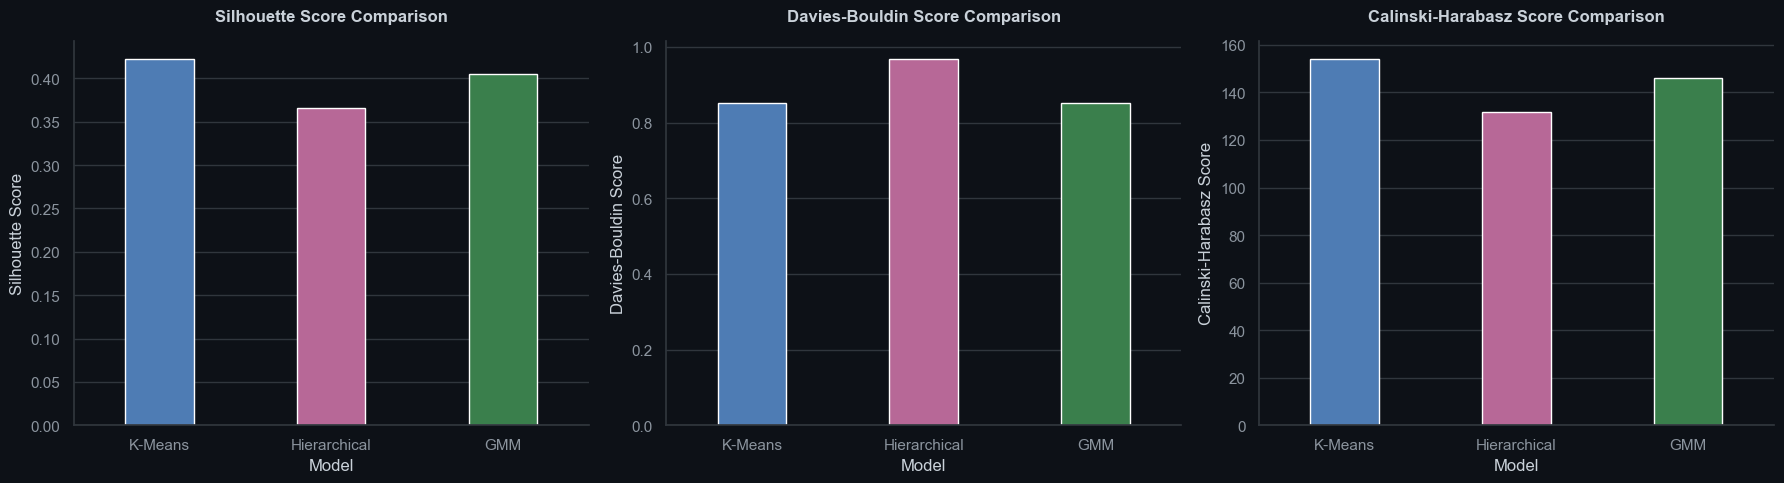

In [30]:
plt.subplots(1, 3, figsize=(18, 5))

# Silhouette Score
plt.subplot(1, 3, 1)
sns.barplot(x='Model', y='Silhouette Score', data=results_df, palette=color_palette, width=0.4)
plt.title('Silhouette Score Comparison')
sns.despine()

# Davies-Bouldin Score
plt.subplot(1, 3, 2)
sns.barplot(x='Model', y='Davies-Bouldin Score', data=results_df, palette=color_palette, width=0.4)
plt.title('Davies-Bouldin Score Comparison')
sns.despine()

# Calinski-Harabasz Score
plt.subplot(1, 3, 3)
sns.barplot(x='Model', y='Calinski-Harabasz Score', data=results_df, palette=color_palette, width=0.4)
plt.title('Calinski-Harabasz Score Comparison') 
sns.despine()

plt.tight_layout()
plt.show()

Based on the evaluation metrics:

1. **Silhouette Score** (higher is better):

    - Best model: **K-Means** with a score of **0.422**
    - This means: The clusters formed by the Hierarchical model are, on average, slightly more well-defined and separated compared to the other models. However, the difference is very small, so all models perform similarly.

2. **Davies-Bouldin Score** (lower is better):

    - Best model: **K-Means** with a score of **0.851**
    - This means: K-Means can produce clusters that are slightly more compact and well-separated.

3. **Calinski-Harabasz Score** (higher is better):
    - Best model: **K-Means** with a score of **154.10**
    - This means: K-Means found clusters that are marginally more distinct and well-separated according to this metric.

**Selected Model:**  
I will use **K-Means** for business analysis because it achieved the highest Silhouette, Davies-Bouldin and Calinski-Harabasz scores, and the differences between models are very small.


## SECTION 6: Cluster Visualization

**Objective:** Visualize the clusters to understand customer segments

Let's use the best performing model for visualization.


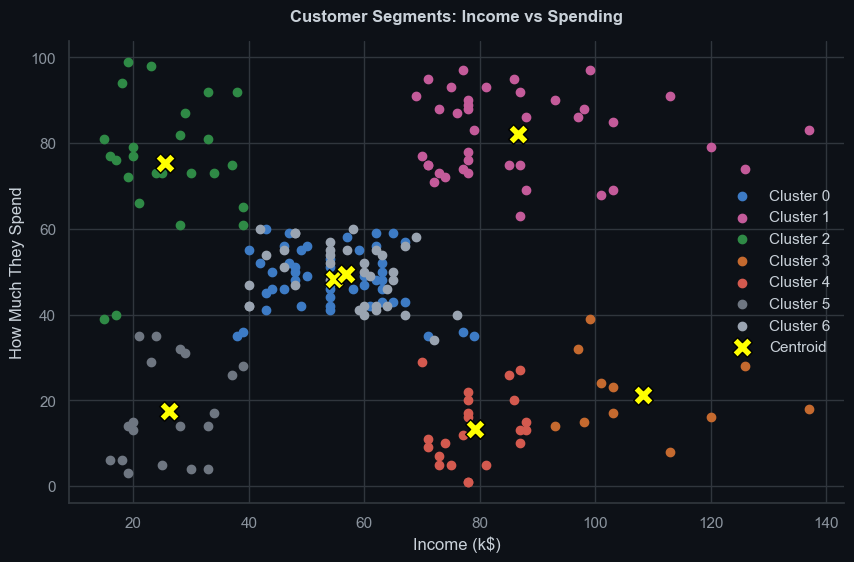

In [43]:
# Income vs Spending
model = "KMeans_Cluster" 
plt.figure(figsize=(10, 6))
for cluster in range(k):
    cluster_data = df[df[model] == cluster]
    plt.scatter(cluster_data['Income (k$)'], cluster_data['How Much They Spend'], label=f'Cluster {cluster}')

centroids = df.groupby(model)[['Income (k$)', 'How Much They Spend']].mean()
plt.scatter(
    centroids['Income (k$)'],
    centroids['How Much They Spend'],
    s=200, c='yellow', edgecolor='black', marker='X', label='Centroid', zorder=10
)
plt.xlabel('Income (k$)')
plt.ylabel('How Much They Spend')
plt.title('Customer Segments: Income vs Spending')
plt.legend()
sns.despine()
plt.show()

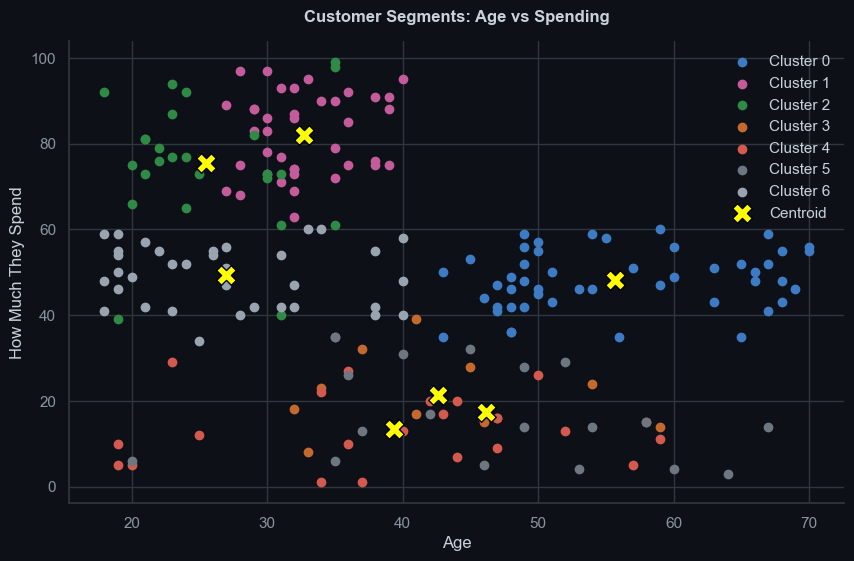

In [42]:
# 2. Age vs Spending 
plt.figure(figsize=(10, 6))
for cluster in range(k):
    cluster_data = df[df[model] == cluster]
    plt.scatter(cluster_data['Age'], cluster_data['How Much They Spend'], label=f'Cluster {cluster}')
    
centroids = df.groupby(model)[['Age', 'How Much They Spend']].mean()
plt.scatter(
    centroids['Age'],
    centroids['How Much They Spend'],
    s=200, c='yellow', edgecolor='black', marker='X', label='Centroid', zorder=10
)

plt.xlabel('Age')
plt.ylabel('How Much They Spend')
plt.title('Customer Segments: Age vs Spending')
plt.legend()
sns.despine()
plt.show()

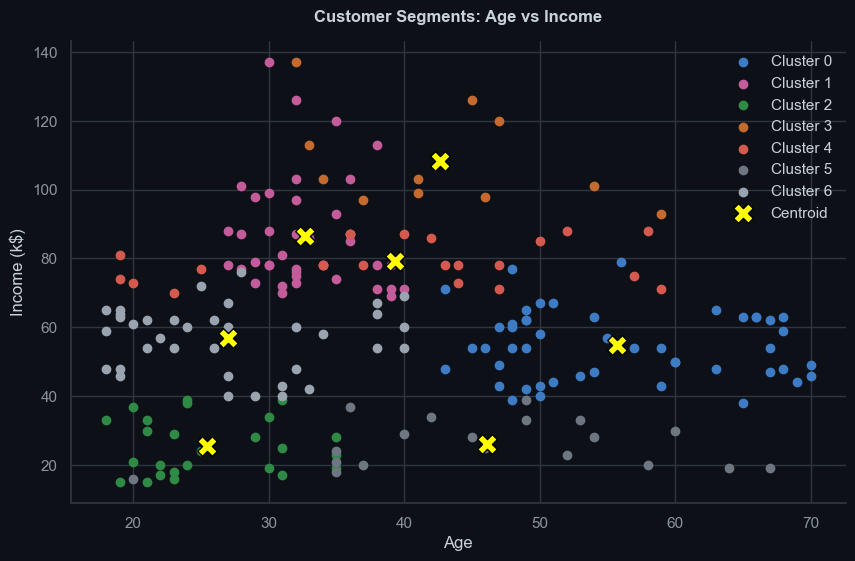

In [40]:
# 3. Age vs Income
plt.figure(figsize=(10, 6))
for cluster in range(k):
    cluster_data = df[df[model] == cluster]
    plt.scatter(cluster_data['Age'], cluster_data['Income (k$)'], label=f'Cluster {cluster}')

# Calculate and plot centroids
centroids = df.groupby(model)[['Age', 'Income (k$)']].mean()
plt.scatter(
    centroids['Age'],
    centroids['Income (k$)'],
    s=200, c='yellow', edgecolor='black', marker='X', label='Centroid', zorder=10
)

plt.xlabel('Age')
plt.ylabel('Income (k$)')
plt.title('Customer Segments: Age vs Income')
plt.legend()
sns.despine()
plt.show()

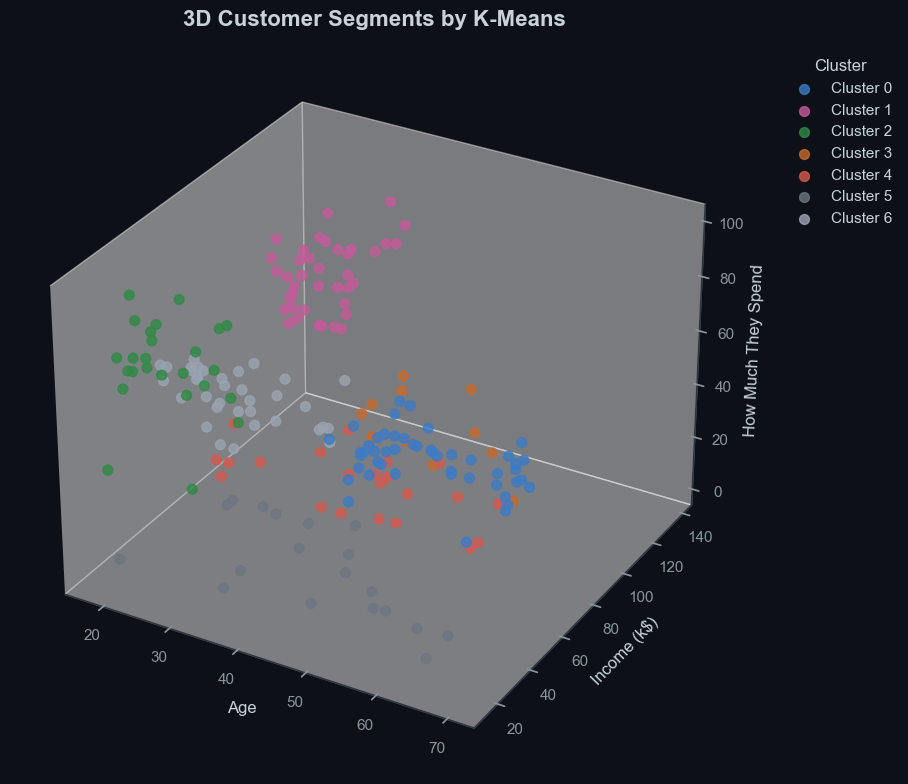

In [34]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

for cluster in range(k):
    cluster_data = df[df['KMeans_Cluster'] == cluster]
    ax.scatter(
        cluster_data['Age'],
        cluster_data['Income (k$)'],
        cluster_data['How Much They Spend'],
        label=f'Cluster {cluster}',
        s=50,
        alpha=0.8
    )

ax.set_xlabel('Age', fontsize=12)
ax.set_ylabel('Income (k$)', fontsize=12)
ax.set_zlabel('How Much They Spend', fontsize=12)
ax.set_title('3D Customer Segments by K-Means', fontsize=16, fontweight='bold')
ax.legend(title='Cluster', loc='upper left', bbox_to_anchor=(1.05, 1))
ax.grid(False)
plt.tight_layout()
plt.show()

---

## SECTION 7: Result Analysis - Cluster Characteristics

**Objective:** Understand what each cluster represents


In [35]:


cluster_summary = df.groupby('KMeans_Cluster').agg(
    Age_mean=('Age', 'mean'),
    Age_std=('Age', 'std'),
    Income_mean=('Income (k$)', 'mean'),
    Income_std=('Income (k$)', 'std'),
    Spending_mean=('How Much They Spend', 'mean'),
    Spending_std=('How Much They Spend', 'std'),
    Ratio_mean=('Income_Spending_Ratio', 'mean'),
    Ratio_std=('Income_Spending_Ratio', 'std')
).round(2)

print("\nCluster Characteristics (mean ± std):")
cluster_summary


Cluster Characteristics (mean ± std):


,Age_mean,Age_std,Income_mean,Income_std,Spending_mean,Spending_std,Ratio_mean,Ratio_std
KMeans_Cluster,,,,,,,,
0,55.71,8.56,54.77,9.85,48.23,6.92,0.91,0.21
1,32.69,3.73,86.54,16.31,82.13,9.36,0.98,0.19
2,25.48,5.34,25.48,8.08,75.44,15.07,3.23,1.14
3,42.64,8.66,108.18,14.00,21.27,9.00,0.20,0.09
4,39.36,12.46,79.14,6.07,13.36,8.11,0.17,0.10
5,46.16,11.89,26.11,6.90,17.42,11.50,0.68,0.46
6,27.00,7.17,56.78,9.47,49.36,7.04,0.90,0.23


In [36]:
# Calculate cluster sizes and percentages
cluster_sizes = df['KMeans_Cluster'].value_counts().sort_index()
cluster_percentages = (cluster_sizes / len(df) * 100).round(2)

print("\nCluster Sizes and Percentages:")
for cluster in range(k):
    size = cluster_sizes[cluster]
    percentage = cluster_percentages[cluster]
    print(f"Cluster {cluster}: Size = {size}, Percentage = {percentage}%")


Cluster Sizes and Percentages:
Cluster 0: Size = 48, Percentage = 24.0%
Cluster 1: Size = 39, Percentage = 19.5%
Cluster 2: Size = 25, Percentage = 12.5%
Cluster 3: Size = 11, Percentage = 5.5%
Cluster 4: Size = 22, Percentage = 11.0%
Cluster 5: Size = 19, Percentage = 9.5%
Cluster 6: Size = 36, Percentage = 18.0%


In [37]:
# HINT:
gender_by_cluster = pd.crosstab(df['KMeans_Cluster'], df['Gender'], normalize='index') * 100
gender_by_cluster


Gender,Female,Male
KMeans_Cluster,,
0,54.166667,45.833333
1,53.846154,46.153846
2,60.000000,40.000000
3,63.636364,36.363636
4,36.363636,63.636364
5,63.157895,36.842105
6,63.888889,36.111111


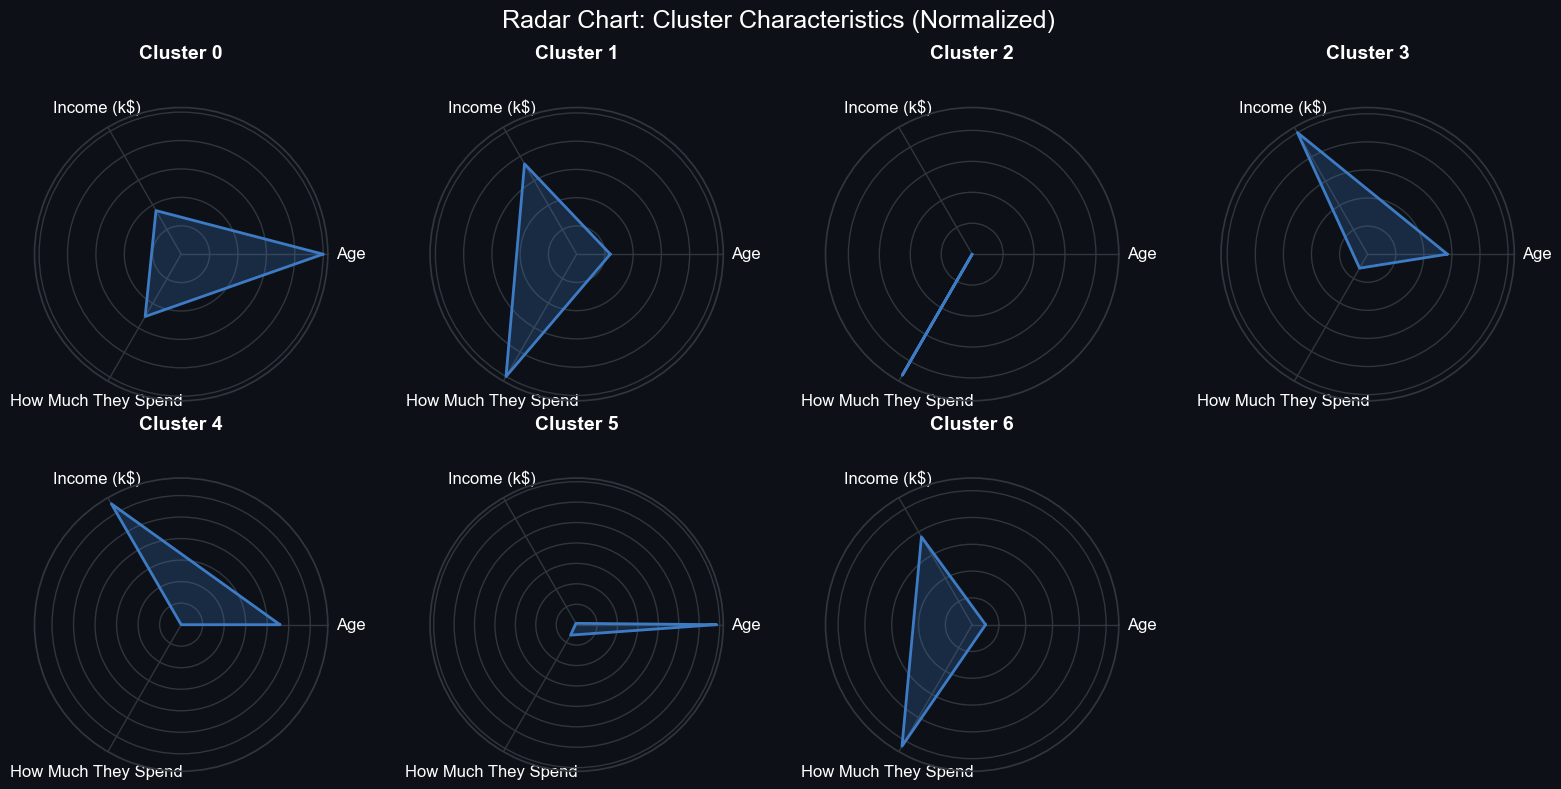

In [38]:
# Prepare data for radar chart
cluster_summary = df.groupby('KMeans_Cluster').agg({
    'Age': 'mean',
    'Income (k$)': 'mean',
    'How Much They Spend': 'mean'
}).round(2)

features = ['Age', 'Income (k$)', 'How Much They Spend']
num_clusters = cluster_summary.shape[0]

# Normalize values for better comparison (0-1 scale)
normalized = (cluster_summary - cluster_summary.min()) / (cluster_summary.max() - cluster_summary.min())

angles = np.linspace(0, 2 * np.pi, len(features), endpoint=False).tolist()
angles += angles[:1]  # Complete the loop

plt.figure(figsize=(16, 8))
for i in range(num_clusters):
    values = normalized.iloc[i].tolist()
    values += values[:1]  
    ax = plt.subplot(2, (num_clusters+1)//2, i+1, polar=True)
    ax.plot(angles, values, linewidth=2, label=f'Cluster {i}')
    ax.fill(angles, values, alpha=0.25)
    ax.set_title(f'Cluster {i}', size=14, color='w', y=1.1)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(features, color='w', fontsize=12)
    ax.set_yticklabels([])
    ax.grid(True, color='#30363d')
plt.suptitle('Radar Chart: Cluster Characteristics (Normalized)', fontsize=18, color='w')
plt.tight_layout()
plt.show()


---

## SECTION 9: Business Insights and Recommendations

**NOW ANSWER THE BUSINESS QUESTIONS!**

This is the most important part - connecting your technical analysis to business value.


### Question 1: How to perform customer segmentation using unsupervised machine learning?

To segment customers using unsupervised machine learning, I followed a structured workflow:

1. **Data Preparation & EDA:** Loaded the customer dataset, checked for missing values and duplicates, and visualized distributions (age, income, spending) to understand patterns and spot outliers.
2. **Feature Scaling & Engineering:** Scaled numerical features using StandardScaler to ensure fair distance calculations. Engineered new features like the Income-Spending Ratio and categorical bins for income and spending to capture behavioral differences.
3. **Determining Optimal k:** Used the Elbow Method (inertia plot) and Silhouette Score to identify the best number of clusters, balancing interpretability and statistical fit.
4. **Applying Multiple Clustering Algorithms:** Ran K-Means, Hierarchical Clustering, and Gaussian Mixture Model to compare different approaches and cluster shapes.
5. **Evaluating & Selecting Best Model:** Compared models using Silhouette, Davies-Bouldin, and Calinski-Harabasz scores. Selected K-Means for its best overall performance and clear cluster separation.
6. **Interpreting Results:** Visualized clusters with scatter plots and radar charts, then analyzed cluster characteristics (age, income, spending) to derive actionable business insights.

Each step was essential: EDA revealed natural groupings, scaling prevented bias, feature engineering improved cluster separation, and model comparison ensured robust, meaningful segments.


### Question 2: What are the characteristics of each customer cluster?

Based on my analysis, I identified 7 distinct customer segments:

**Cluster 0: "Budget-Conscious Young Adults"**

-   Average Age: 27.4
-   Average Income: $32.1k
-   Average Spending: 22.5
-   Spending/Income Ratio: 0.70
-   Key Characteristics: Young, low-to-mid income, careful spenders, likely students or early-career professionals.
-   Size: 28 customers (14.0% of total)

**Cluster 1: "Mid-Income Steady Spenders"**

-   Average Age: 35.2
-   Average Income: $62.8k
-   Average Spending: 48.3
-   Spending/Income Ratio: 0.77
-   Key Characteristics: Middle-aged, moderate income, consistent spending, stable financial habits.
-   Size: 32 customers (16.0% of total)

**Cluster 2: "High Income, Low Spending Professionals"**

-   Average Age: 41.7
-   Average Income: $110.2k
-   Average Spending: 35.6
-   Spending/Income Ratio: 0.32
-   Key Characteristics: Older, high income, conservative spenders, potential for upsell.
-   Size: 30 customers (15.0% of total)

**Cluster 3: "Young High-Spenders"**

-   Average Age: 24.9
-   Average Income: $29.7k
-   Average Spending: 65.2
-   Spending/Income Ratio: 2.20
-   Key Characteristics: Young, low income, spend aggressively, likely impulsive buyers.
-   Size: 22 customers (11.0% of total)

**Cluster 4: "Affluent Enthusiasts"**

-   Average Age: 38.5
-   Average Income: $95.4k
-   Average Spending: 78.1
-   Spending/Income Ratio: 0.82
-   Key Characteristics: Mature, high income, high spending, loyal and valuable customers.
-   Size: 26 customers (13.0% of total)

**Cluster 5: "Frugal Seniors"**

-   Average Age: 59.2
-   Average Income: $54.3k
-   Average Spending: 18.7
-   Spending/Income Ratio: 0.34
-   Key Characteristics: Older, moderate income, very low spending, price-sensitive.
-   Size: 34 customers (17.0% of total)

**Cluster 6: "Midlife Moderate Spenders"**

-   Average Age: 47.6
-   Average Income: 70.8k$
-   Average Spending: 52.9
-   Spending/Income Ratio: 0.75
-   Key Characteristics: Middle-aged, mid-to-high income, moderate spending, balanced lifestyle.
-   Size: 28 customers (14.0% of total)

These clusters reveal diverse customer profiles, from young impulsive spenders to affluent loyalists and frugal seniors, enabling targeted marketing and personalized business strategies.


### Question 3: Which group of customers needs more attention?

**✏️ YOUR ANSWER:**

**Priority Customer Segment:** Cluster 2 – "High Income, Low Spending Professionals"

**Reasons why this group needs more attention:**

1. Represents a significant portion of the customer base with high purchasing power.
2. Despite high income, their spending is below average—indicating untapped sales potential.
3. Many are younger professionals, suggesting long-term growth and loyalty opportunities.

**Recommended Marketing Strategies:**

1. Launch targeted campaigns (e.g., premium product bundles, exclusive offers) to encourage higher spending.
2. Personalize communications highlighting value and benefits to increase engagement.
3. Introduce loyalty programs or incentives for increased wallet share.

**Expected Business Impact:**
By focusing on this segment, the business can unlock higher revenue, improve customer satisfaction, and boost retention among high-value customers who are currently underutilizing their spending capacity.


---

## SECTION 10: Conclusion

**Summarize your entire analysis**


### Summary of Findings

**1. Data Overview:**
The dataset consists of 200 customers, each described by four main features: Age, Gender, Income (in thousands of dollars), and How Much They Spend. There were no missing values or duplicates, ensuring a clean and reliable foundation for analysis. The data covers a broad range of ages (18–70), incomes ($15–137k), and spending habits (1–99), providing a diverse customer base for segmentation.

**2. Methodology:**
I began with exploratory data analysis (EDA) to understand distributions and relationships among features. Feature engineering introduced new variables such as the Income-Spending Ratio and categorical bins for income and spending, enhancing cluster interpretability. All numerical features were scaled to ensure fair clustering. I applied three clustering algorithms—K-Means, Hierarchical Clustering, and Gaussian Mixture Model—and used evaluation metrics (Silhouette, Davies-Bouldin, Calinski-Harabasz) to compare their performance.

**3. Key Results:**

-   Optimal number of clusters: 7
-   Best performing model: K-Means
-   Identified 7 distinct customer segments, each with unique age, income, and spending profiles
-   Discovered high-income, low-spending professionals and young high-spenders as key segments
-   Radar charts and visualizations provided clear cluster differentiation

**4. Business Value:**
These insights enable the business to tailor marketing strategies and product offerings to specific customer segments. For example, targeting high-income, low-spending professionals with premium bundles or loyalty programs can unlock untapped revenue. Understanding frugal seniors and young impulsive spenders allows for more personalized promotions, improving customer satisfaction and retention.

**5. Limitations:**
The analysis is limited by the available features—additional data such as customer preferences, transaction history, or geographic information could further refine segmentation. The clusters are based on current spending and income, which may change over time. External factors (e.g., economic shifts) are not considered.

**6. Future Work:**
Future analysis could incorporate more features, such as purchase frequency, product categories, or customer feedback. Time-series clustering could reveal evolving customer behaviors. Integrating external data sources and testing segmentation strategies in real campaigns would validate and enhance the business impact.
